In [3]:
x = [1, 2, 3]
print(x * 2)

[1, 2, 3, 1, 2, 3]


In [5]:
import numpy as np
x =np.array([1,2,3])
print(x*2)

[2 4 6]


In [4]:
import numpy as np
x = np.array([2,4,6,8,10,12])
y = np.array([1,3,5,7,9,11])
xx = 12

n = len(x)
r = 0
for i in range(n):
    s = y[i]
    for j in range(n):
        if i != j:
            s = s*((xx - x[j]) / (x[i] - x[j]))
    r = r + s
print(r)            
            


11.0


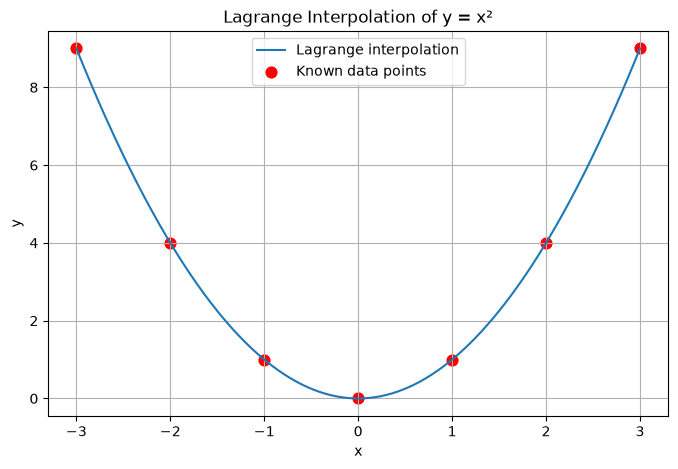

In [18]:

import numpy as np
import matplotlib.pyplot as plt

# Known data points
x = np.array([-3, -2, -1, 0, 1, 2, 3])
y = x**2

# Lagrange interpolation function
def Lagrng(x, y, xx):
    n = len(x)
    r = 0

    for i in range(n):
        s = y[i]

        for j in range(n):
            if i != j:
                s = s * ((xx - x[j]) / (x[i] - x[j]))

        r = r + s

    return r

# Generate x-coordinates for plotting
x_plot = np.linspace(-3, 3, 300)

# Calculate interpolated y-coordinates
y_plot = np.array([Lagrng(x, y, z) for z in x_plot])

# Plot the curve and known points
plt.figure(figsize=(8, 5))

plt.plot(x_plot, y_plot, label="Lagrange interpolation")
plt.scatter(x, y, color="red", s=60, label="Known data points")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Lagrange Interpolation of y = x²")
plt.grid(True)
plt.legend()
plt.show()

In [6]:
# random number generator for NACA 4-digit airfoil
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()
c = rng.choice([0.00, 0.01, 0.02, 0.03, 0.04])
x = rng.choice([0.2, 0.3, 0.4, 0.5, 0.6])
t = rng.choice([0.06, 0.08, 0.10, 0.12, 0.14, 0.16, 0.18, 0.20, 0.22, 0.24, 0.26, 0.28, 0.30])

C = int(round(c*100))
X = int(round(x*10))
T = int(round(t*10))

print("NACA airfoil: NACA {}{}{:02d}".format(C, X, T))
print("Maximum camber,  c =", c)
print("Location of maximum camber, x =", x)
print("Maximum thickness ratio, t =", t)




NACA airfoil: NACA 2201
Maximum camber,  c = 0.02
Location of maximum camber, x = 0.2
Maximum thickness ratio, t = 0.14


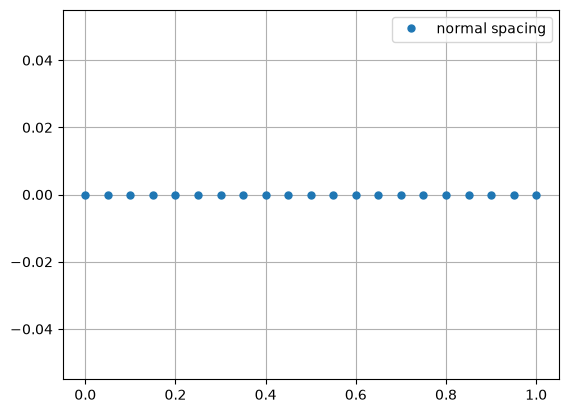

In [14]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(0, 1, 21)
plt.plot(x, np.zeros(21), "o", markersize=5,
         label="normal spacing")
plt.grid(True)
plt.legend()
plt.show()


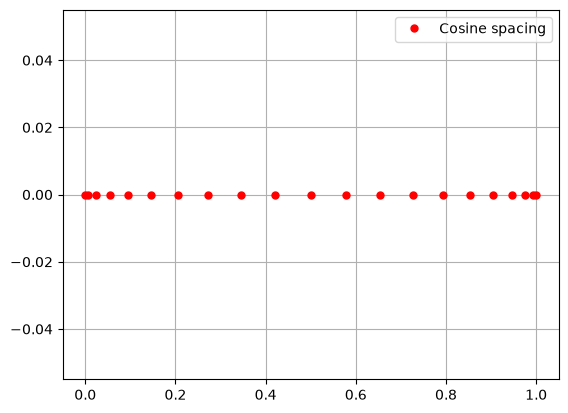

In [6]:
import numpy as np
import matplotlib.pyplot as plt
beta = np.linspace(0, np.pi, 21)
x = (1 - np.cos(beta)) / 2
plt.plot(x, np.zeros(21), "o",color = "r", markersize=5,linestyle="none",
         label="Cosine spacing")
plt.grid(True)
plt.legend()
plt.show()

# we need more points near the leading and trailing edge for the curve to act 
# smooth on any interpolation methods. so we choose cosine spacing.

NACA airfoil: NACA 0315
Maximum camber  c = 0.0
Location of maximum camber x = 0.3
Maximum thickness ratio t = 0.15


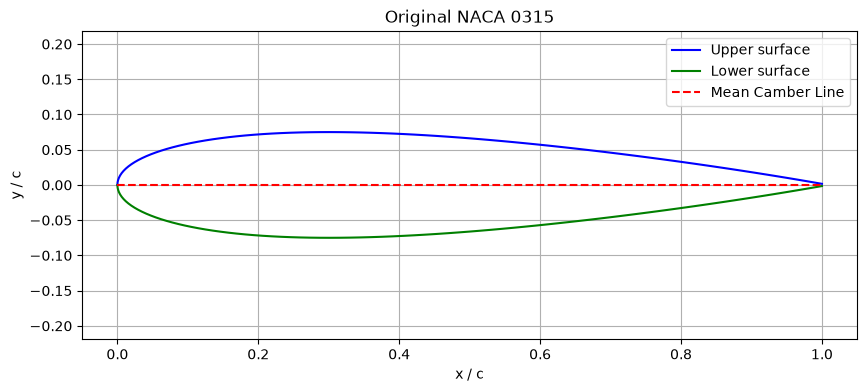

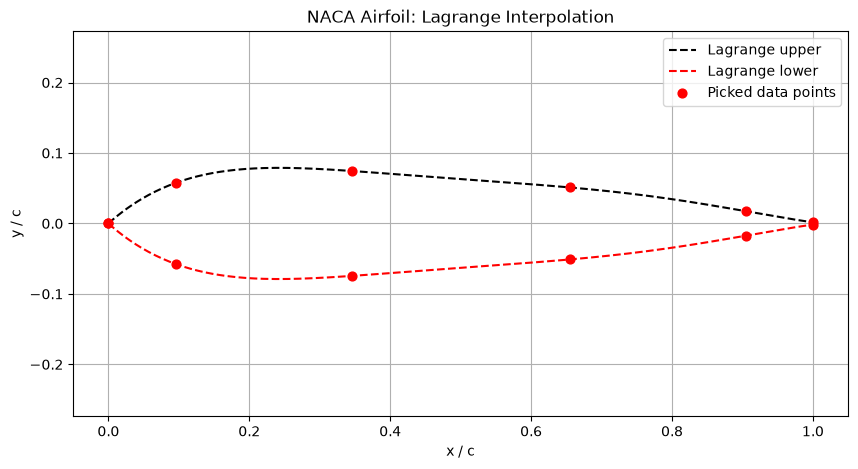

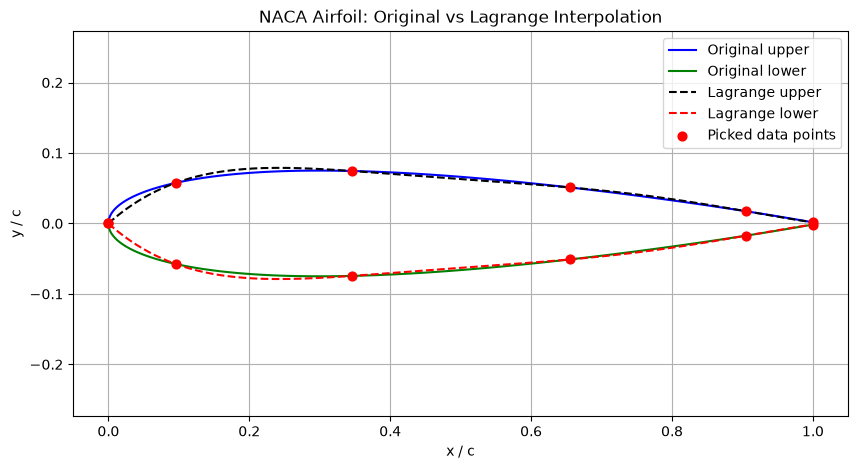

[0.        0.0954915 0.3454915 0.6545085 0.9045085 1.       ]
[0.         0.05756117 0.0744684  0.05114676 0.0173929  0.001575  ]
[0.        0.0954915 0.3454915 0.6545085 0.9045085 1.       ]
[ 0.         -0.05756117 -0.0744684  -0.05114676 -0.0173929  -0.001575  ]
NACA Airfoil: 0315

UPPER SURFACE
Maximum absolute error: 0.013137327078822432
RMS error: 0.0036915040373159437

LOWER SURFACE
Maximum absolute error: 0.013137327078822432
RMS error: 0.0036915040373159437

COMBINED AIRFOIL
Maximum absolute error: 0.013137327078822432
RMS error: 0.0036915040373159437


In [1]:
# random number generator for NACA 4-digit airfoil
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

m = rng.choice([0.00, 0.01, 0.02, 0.03, 0.04])
p = rng.choice([0.2, 0.3, 0.4, 0.5])
t = rng.choice([0.08, 0.10, 0.12, 0.15])

M = int(round(m * 100))
P = int(round(p * 10))
T = int(round(t * 100))


print("NACA airfoil: NACA {}{}{:02d}".format(M, P, T))
print("Maximum camber  c =", m)
print("Location of maximum camber x =", p)
print("Maximum thickness ratio t =", t)
  

       #########################################################################

# Original NACA airfoil plotting

# Chordwise locations
N = 101
beta = np.linspace(0, np.pi, N)
x = (1 - np.cos(beta)) / 2

# Thickness distribution
yt = 5 * t * (
    0.2969 * np.sqrt(x)
    - 0.1260 * x
    - 0.3516 * x**2
    + 0.2843 * x**3
    - 0.1015 * x**4)


# Mean camber line and its slope
yc = np.zeros(N)
dyc = np.zeros(N)

for i in range(N):
    if x[i] <= p:
        yc[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
        dyc[i] = (2*m / p**2) * (p - x[i])
    else:
        yc[i] = (m / (1-p)**2) * (
            (1 - 2*p) + 2*p*x[i] - x[i]**2)
        dyc[i] = (2*m / (1-p)**2) * (p - x[i])

theta = np.arctan(dyc)

xu = x - yt * np.sin(theta)
yu = yc + yt * np.cos(theta)

xl = x + yt * np.sin(theta)
yl = yc - yt * np.cos(theta)


plt.figure(figsize=(10, 4))

plt.plot(xu, yu, label="Upper surface", color="blue")
plt.plot(xl, yl, label="Lower surface", color="green")
plt.plot(x, yc, "--", label="Mean Camber Line", color="red")

plt.xlabel("x / c")
plt.ylabel("y / c")
plt.title("Original NACA {}{}{:02d}".format(M, P, T))
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


        #########################################################################


# Select six points from each surface
N_points = 6
indices = np.linspace(0, N-1, N_points, dtype=int)

x_upper = xu[indices]
y_upper = yu[indices]

x_lower = xl[indices]
y_lower = yl[indices]

          
#########################################################################################

# Lagrange interpolation

def Lagrng(x,y,xx):
    n = len(x)
    r = 0
    for i in range(n):
         s = y[i]
         for j in range(n):
             if i != j:
                 s = s*((xx - x[j]) / (x[i] - x[j]))
         r = r + s
    return r

        
        ##########################################################################


# Plotting the reconstructed airfoil
xx = np.linspace(0, 1, 300)

yu_lag = np.array([Lagrng(x_upper, y_upper, z) for z in xx])
yl_lag = np.array([Lagrng(x_lower, y_lower, z) for z in xx])


plt.figure(figsize=(10, 5))

plt.plot(xx, yu_lag, "--", label="Lagrange upper", color="black")
plt.plot(xx, yl_lag, "--", label="Lagrange lower", color="red")

plt.scatter(x_upper, y_upper, color="red", s=40, label="Picked data points", zorder=3)
plt.scatter(x_lower, y_lower, color="red", s=40, zorder=3)

plt.xlabel("x / c")
plt.ylabel("y / c")
plt.title("NACA Airfoil: Lagrange Interpolation")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


      ##########################################################################


# Plotting the original and reconstructed airfoil
plt.figure(figsize=(10, 5))

plt.plot(xu, yu, label="Original upper", color="blue")
plt.plot(xl, yl, label="Original lower", color="green")

plt.plot(xx, yu_lag, "--", label="Lagrange upper", color="black")
plt.plot(xx, yl_lag, "--", label="Lagrange lower", color="red")

plt.scatter(x_upper, y_upper, color="red", s=40, label="Picked data points", zorder=3)
plt.scatter(x_lower, y_lower, color="red", s=40, zorder=3)

plt.xlabel("x / c")
plt.ylabel("y / c")
plt.title("NACA Airfoil: Original vs Lagrange Interpolation")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

    ##########################################################################


print(x_upper)
print(y_upper)
print(x_lower)
print(y_lower)

# Error calculation
yu_original = np.interp(xx, xu, yu)
yl_original = np.interp(xx, xl, yl)

error_upper = yu_original - yu_lag
error_lower = yl_original - yl_lag

max_error_upper = np.max(np.abs(error_upper))
max_error_lower = np.max(np.abs(error_lower))

rms_upper = np.sqrt(np.mean(error_upper**2))
rms_lower = np.sqrt(np.mean(error_lower**2))

all_errors = np.concatenate((error_upper, error_lower))

max_error_combined = np.max(np.abs(all_errors))
rms_combined = np.sqrt(np.mean(all_errors**2))

print("NACA Airfoil: {}{}{:02d}".format(M, P, T))

print("\nUPPER SURFACE")
print("Maximum absolute error:", max_error_upper)
print("RMS error:", rms_upper)

print("\nLOWER SURFACE")
print("Maximum absolute error:", max_error_lower)
print("RMS error:", rms_lower)

print("\nCOMBINED AIRFOIL")
print("Maximum absolute error:", max_error_combined)
print("RMS error:", rms_combined)






